# Exercice 5 : un RNN qui génère du texte
Objectif : prédire le mot suivant à partir de 3 mots précédents, puis écrire un texte mot après mot. Prépare un fichier textes.txt (UTF-8), avec un texte par ligne.

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, LSTM
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
TEXTE = "../data-sources/corpus.txt"

In [47]:
with open(TEXTE, 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip()]
print(f"Exemple de texte : {texts[0]}")

vocab_size = 1800
window_size = 3

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

Exemple de texte : Le chat dort paisiblement sur le canapé du salon.


In [48]:
# Exemples d'apprentissage : au plus 3 mots précédents -> mot suivant
X, y = [], []
for seq in sequences:
    for i in range(1, len(seq)):
        X.append(seq[max(0, i-window_size):i])
        y.append(seq[i])
X = pad_sequences(X, maxlen=window_size, padding='pre')
y = np.array(y)
print(f"X shape : {X.shape}, y shape : {y.shape}")

X shape : (1298, 3), y shape : (1298,)


In [57]:
embedding_dim = 16
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    SimpleRNN(32),
    # LSTM(64),
    Dense(vocab_size, activation='softmax'),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

Epoch 1/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0277 - loss: 7.4633
Epoch 2/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0293 - loss: 6.6837
Epoch 3/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0439 - loss: 5.7980 
Epoch 4/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0439 - loss: 5.6946
Epoch 5/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0439 - loss: 5.6525 
Epoch 6/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0439 - loss: 5.6133
Epoch 7/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0439 - loss: 5.5815
Epoch 8/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0439 - loss: 5.5491
Epoch 9/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0462 - loss: 5.5149 
Epoch 10/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0601 - loss: 5.4765
Epoch 11/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.0601 - loss: 5.4291 
Epoch 12/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accur

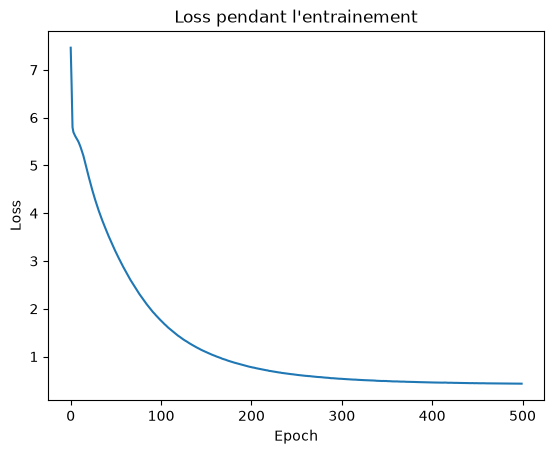

In [58]:
early_stop = EarlyStopping(monitor="loss", patience=10, restore_best_weights=True)
history = model.fit(X, y, epochs=500, batch_size=32, callbacks=[early_stop])

plt.plot(history.history["loss"])
plt.title("Loss pendant l'entrainement")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [51]:
def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        # même format qu'à l'entrainement : les 3 derniers mots seulement
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding="pre")
        probs = model.predict(tokens, verbose=0)[0]

        # tirage au sort pondéré (température < 1 : plus sur, > 1 plus varié)
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word = tokenizer.index_word.get(index)
        if word is not None: # l'indice 0 sert au bourrage, pas un mot TODO apocompris
            text += " " + word
    return text

In [60]:
print(generate_text("Le poête", num_words=50, temperature=0.2))

Le poête vieux moulin tourne encore grâce au vent du bœuf tous un pain italien sa l’heure lettre la mer bibliothèque le long sont la saison du dauphiné et elle matin dans un fromages depuis ce colline qu’un les fleurs merveilleuses à commencent pour manger le soir en été et soi aller


- SimpleRNN : Simple et rapide, mais incapable de mémoriser des dépendances longues.
- LSTM : Complexe et lent, mais excellente mémoire à long terme, idéal pour les séquences longues.

SimpleRNN(32) :
Epoch 500/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8074 - loss: 0.4330

LSTM(64) :
Epoch 419/500
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8105 - loss: 0.4280

SimpleRNN, T=0.8
> Le poête vieux château domine la vallée depuis la colline italien le ciel prix bordé du vraiment enfant livres écrit autres tourne des bourgeons dans le jours municipale après lire nos déchets pour le ciel famille montagne après aux baignades parcours un pour à génération scolaire l’école primaire six lentement vocabulaire mangeoires

SimpleRNN, T=0.2
> Le poête vieux moulin tourne encore grâce au vent du bœuf tous un pain italien sa l’heure lettre la mer bibliothèque le long sont la saison du dauphiné et elle matin dans un fromages depuis ce colline qu’un les fleurs merveilleuses à commencent pour manger le soir en été et soi aller

LSTM(64), T=0.8
> Le poête train de montagne offre une vue panoramique avant migrateurs arbres simple et coloré parcours à bonhomme de toute le région examens l’école jouent aux l’esprit avec le deviennent classique vitesse saison les piano en hiver dans les tables au printemps dans les beaux au printemps mortes dans saison pain entier

LSTM(64), T=0.2
> Le poête marché du village a lieu tous les samedis matin simple du mois amis un pain publics interlocuteur soir intéressant des quinze lettre une municipale examens son réputé à une lire à la écrire entre des objets depuis depuis heures quinze quinze lettre depuis ans salade quinze le jardin depuis ce

LSTM(64), T=1.4
> Le poête boulanger pétrit la pâte à la main chaque matin empruntables du célèbre blanc un sauf jouant pour la soir avant la dormir se enfants pour la vent littéraire était passionnant restaurant cour l’heure réputé de ancien très mère pédagogique préparer les arroser les neige pour jardin la vent ville était

LSTM(64), T=12
> Le poête étions parcours gratuitement monde parc chien chouette patience faire correspondant importante l’heure le tableaux boire âge dos quatre voisin d’un la musique langues éclore passe pluie interdit villes voiture qui trois

## QUESTIONS

**1. Que fait `Tokenizer` et pourquoi est-il nécessaire avec un RNN ?**

Le `Tokenizer` transforme le texte en nombres. Un RNN ne comprend que des chiffres, pas des mots : il découpe le texte en mots, attribue un numéro à chacun, puis convertit les phrases en listes de numéros.

```
"Le chat dort"  →  [12, 45, 78]  →  le RNN peut traiter
```

Sans lui, le RNN ne pourrait rien faire avec du texte.

**2. Pourquoi utilise-t-on `pad_sequences`, que se passerait-il sans lui ?**

`pad_sequences` ajoute des 0 pour que toutes les séquences aient la même longueur.

- Les phrases courtes sont complétées avec des 0 au début
- Les phrases longues sont déjà découpées en amont par `window_size = 3`

Sans `pad_sequences`, les entrées auraient des tailles différentes et le RNN ne pourrait pas les traiter ensemble.

**3. Quelle est la différence entre `vocab_size` et `embedding_size` ?**

- **`vocab_size`** = le nombre de mots dans le vocabulaire (1800 dans le code). Ça limite le dictionnaire : on garde seulement les 1800 mots les plus fréquents.

- **`embedding_size`** = la taille du vecteur qui représente chaque mot (16 dans le code). Chaque mot devient un vecteur de 16 nombres.

En résumé : `vocab_size` dit **combien de mots** on connaît, `embedding_size` dit **en combien de dimensions** on représente chaque mot.

**4. En quoi consiste une couche d'embedding ? Pourquoi est-elle placée avec la couche RNN ?**

**La couche d'embedding** transforme chaque mot (représenté par un numéro) en un **vecteur de nombres** (par exemple 16 nombres). Ces vecteurs sont appris pendant l'entraînement : les mots avec des sens proches auront des vecteurs similaires.

**Pourquoi avec le RNN ?** Le RNN ne peut pas traiter directement des numéros de mots (1, 2, 3...). Il a besoin de vecteurs continus pour calculer des similarités et apprendre des relations entre les mots. L'embedding fournit cette représentation dense et apprise, que le RNN peut ensuite traiter.

**5. Quelle est la différence entre SimpleRNN et LSTM ? Dans quel cas préférer un LSTM ?**

**SimpleRNN** est basique : il lit la séquence mot par mot et oublie vite ce qu'il a vu au début. Il souffre du problème de **vanishing gradient** (les gradients deviennent trop petits pour apprendre les dépendances longues).

**LSTM** (Long Short-Term Memory) a une mémoire interne plus sophistiquée avec des "portes" (oubli, entrée, sortie) qui contrôlent quoi garder et quoi oublier. Il retient mieux les informations sur le long terme.

**Quand préférer un LSTM ?** Quand les séquences sont longues et que les dépendances entre mots éloignés sont importantes (ex : comprendre le sujet d'une phrase au début pour prédire la fin).

**6. Que représente `window_size = 3` et comment influence-t-il l'apprentissage ?**

`window_size = 3` signifie que le modèle regarde **les 3 derniers mots** pour prédire le mot suivant.

**Influence sur l'apprentissage :**

- **Plus petit** (ex: 1 ou 2) → le modèle voit moins de contexte, il prédit surtout des mots fréquents et simples, le texte généré est moins cohérent.

- **Plus grand** (ex: 10 ou 20) → le modèle voit plus de contexte, il peut mieux capturer la structure des phrases, mais l'entraînement est plus lent et il faut plus de données.

Avec 3, c'est un compromis : assez de contexte pour des phrases simples, pas trop pour rester rapide.

**7. Pourquoi utiliser `sparse_categorical_crossentropy` dans ce cas précis ?**

`sparse_categorical_crossentropy` est utilisée quand :
- On a **plusieurs classes** (ici : tous les mots du vocabulaire, ex: 1800)
- Les labels sont des **entiers** (le numéro du mot à prédire), pas des vecteurs one-hot

**Pourquoi "sparse" ?** Parce qu'on ne stocke qu'un seul entier par exemple (ex: `42` = le mot "chat"), au lieu d'un vecteur de 1800 valeurs avec un seul 1 (one-hot). C'est plus léger en mémoire.

**Pourquoi pas `categorical_crossentropy` ?** Parce que nos labels `y` sont des entiers simples (`y = [5, 12, 3, ...]`), pas des vecteurs one-hot. `sparse_` fait la conversion automatiquement.

**8. Que fait le callback `EarlyStopping` et pourquoi est-il utile ici ?**

`EarlyStopping` surveille une métrique (ici la `loss` sur les données de validation) pendant l'entraînement. Si cette métrique **n'améliore plus** pendant un certain nombre d'époques (`patience`), il **arrête l'entraînement automatiquement**.

**Pourquoi c'est utile ici ?**
- Évite le **surapprentissage** (overfitting) : le modèle continue d'apprendre sur les données d'entraînement mais dégrade ses performances sur des données nouvelles
- **Gagne du temps** : pas besoin d'attendre les 500 époques si le modèle a déjà convergé
- **Garde le meilleur modèle** : avec `restore_best_weights=True`, il restaure les poids de la meilleure époque

**9. En observant la courbe de la loss, comment savoir si le modèle converge bien ?**

Une bonne convergence se voit quand :

- **La loss diminue** au fil des époques (elle descend)
- **La courbe s'aplatit** progressivement (elle ralentit sa descente)
- **La loss de validation suit la même tendance** que la loss d'entraînement (pas d'écart qui se creuse)

**Signes de problèmes :**
- La loss **stagne** dès le début → le modèle n'apprend pas (learning rate trop faible, ou problème de données)
- La loss **remonte** → surapprentissage (overfitting)
- La loss de validation **monte** pendant que celle d'entraînement descend → surapprentissage aussi

**En résumé :** une courbe qui descend puis s'aplatit doucement = bonne convergence.

**10. Analyser le texte généré; est-il grammaticalement correct et cohérent ? Pourquoi le modèle n'écrit-il pas encore comme un auteur ?**

**Le texte généré n'est pas grammaticalement correct ni cohérent.** On voit des suites de mots qui n'ont pas de sens global :

> *"Le poête vieux château domine la vallée depuis la colline italien le ciel prix bordé du vraiment enfant livres écrit autres tourne des bourgeons dans le jours..."*

**Pourquoi ?**

- **Le modèle prédit mot par mot**, sans vision globale de la phrase. Il choisit le mot le plus probable localement, pas le meilleur pour la phrase entière.

- **Il n'a pas de compréhension sémantique** : il ne sait pas ce qu'est un "poète", une "vallée" ou une "colline". Il manipule juste des statistiques de co-occurrence.

- **Le corpus est petit** : avec peu de données, le modèle n'a pas assez d'exemples pour apprendre des structures grammaticales solides.

- **`window_size = 3` est limité** : il ne voit que 3 mots de contexte, insuffisant pour capturer la cohérence à long terme d'un texte.

- **Pas de mécanisme d'attention** : un SimpleRNN/LSTM seul peine à retenir les dépendances longues (sujet au début, verbe à la fin...).

**En résumé** : le modèle génère du "faux texte" qui *ressemble* à du français statistiquement, mais sans véritable compréhension ni planification.